In [1]:
import numpy as np
import pandas as pd
import machinegnostics

In [2]:
print(machinegnostics.__version__)

0.0.7


# Data Loading and Processing

In [3]:
# read file from the github link
# https://github.com/kamleshparmar17/Advanced_PulseHeatPipe_krp/blob/main/data/database/database.csv
url = "https://raw.githubusercontent.com/kamleshparmar17/Advanced_PulseHeatPipe_krp/main/data/database/database.csv"
db = pd.read_csv(url)
db.head()

# save data 
db.to_csv("database.csv", index=False)

In [4]:
db.keys()

Index(['TIME', 'DATE', 'TC_1', 'TC_2', 'TC_3', 'TC_4', 'TC_5', 'TC_6', 'TC_7',
       'TC_8', 'TC_9', 'PRESSURE', 'HEATER', 'HEATER SET POINT', 'date',
       'voltage', 'current', 'power', 'WF', 'FR[%]', 'Q[W]', 'alpha', 'beta',
       'pulse', 'Te_mean[C]', 'Tc_mean[C]', 'Te_std[C]', 'Tc_std[C]', 'P[bar]',
       'Te_mean[K]', 'Tc_mean[K]', 'Te_std[K]', 'Tc_std[K]', 'T_pulse[K]',
       'TR[K/W]', 'GFE_Te[KJ/mol]', 'GFE_Tc[KJ/mol]', 'dG[KJ/mol]'],
      dtype='str')

In [239]:
drop_columns = ['TC_1', 'TC_2', 'TC_3', 'TC_4', 'TC_5', 'TC_6', 'TC_7',
       'TC_8', 'TC_9', 'GFE_Te[KJ/mol]', 'GFE_Tc[KJ/mol]', 'dG[KJ/mol]', 
       'TIME', 'DATE', 'date', 'voltage', 'current', 'HEATER', 'HEATER SET POINT', 'power',
       'pulse', 'Te_mean[C]', 'Tc_mean[C]', 'P[bar]',
       'Te_std[C]', 'Tc_std[C]', 'PRESSURE', 'Te_std[K]', 'Tc_std[K]', 'Tc_mean[K]']  # replace with actual column names

df = db.drop(columns=drop_columns)

# drop duplicate rows
df = df.drop_duplicates()
df.head()

,WF,FR[%],Q[W],alpha,beta,Te_mean[K],T_pulse[K],TR[K/W]
0,DI water,60,40,0,0,307.43,353.75,0.09
8,DI water,60,40,0,0,307.51,353.75,0.09
11,DI water,60,40,0,0,307.59,353.75,0.09
12,DI water,60,40,0,0,307.61,353.75,0.09
14,DI water,60,40,0,0,307.69,353.75,0.09


In [ ]:
# applying filter for specific conditions
alpha = 90
df_Q40_DIW_a90_b0 = df[(df['Q[W]'] == 40) & (df['WF'] == 'DI water') & (df['alpha'] == alpha) & (df['beta'] == 0)]
df_Q60_DIW_a90_b0 = df[(df['Q[W]'] == 60) & (df['WF'] == 'DI water') & (df['alpha'] == alpha) & (df['beta'] == 0)]
df_Q80_DIW_a90_b0 = df[(df['Q[W]'] == 80) & (df['WF'] == 'DI water') & (df['alpha'] == alpha) & (df['beta'] == 0)]
df_Q100_DIW_a90_b0 = df[(df['Q[W]'] == 100) & (df['WF'] == 'DI water') & (df['alpha'] == alpha) & (df['beta'] == 0)]
df_Q120_DIW_a90_b0 = df[(df['Q[W]'] == 120) & (df['WF'] == 'DI water') & (df['alpha'] == alpha) & (df['beta'] == 0)]

In [241]:
# Te_mean[K] mean for each df
df_Q40_DIW_a90_b0_T_mean = df_Q40_DIW_a90_b0['Te_mean[K]'].median()
df_Q60_DIW_a90_b0_T_mean = df_Q60_DIW_a90_b0['Te_mean[K]'].median()
df_Q80_DIW_a90_b0_T_mean = df_Q80_DIW_a90_b0['Te_mean[K]'].median()
df_Q100_DIW_a90_b0_T_mean = df_Q100_DIW_a90_b0['Te_mean[K]'].median()
df_Q120_DIW_a90_b0_T_mean = df_Q120_DIW_a90_b0['Te_mean[K]'].median()
# print
print(df_Q40_DIW_a90_b0_T_mean)
print(df_Q60_DIW_a90_b0_T_mean)
print(df_Q80_DIW_a90_b0_T_mean)
print(df_Q100_DIW_a90_b0_T_mean)
print(df_Q120_DIW_a90_b0_T_mean)

343.76
351.35
362.55
365.27
363.11


In [391]:
# temperature filter for Te_mean[K] around t (350)
t= 350
t_1 = t + 1
temp = 'Te_mean[K]'
df_Q40_DIW_a90_b0_T =df_Q40_DIW_a90_b0[(df_Q40_DIW_a90_b0[temp] >= t) & (df_Q40_DIW_a90_b0[temp] <= t_1)].drop_duplicates()
df_Q60_DIW_a90_b0_T =df_Q60_DIW_a90_b0[(df_Q60_DIW_a90_b0[temp] >= t) & (df_Q60_DIW_a90_b0[temp] <= t_1)].drop_duplicates()
df_Q80_DIW_a90_b0_T =df_Q80_DIW_a90_b0[(df_Q80_DIW_a90_b0[temp] >= t) & (df_Q80_DIW_a90_b0[temp] <= t_1)].drop_duplicates()
df_Q100_DIW_a90_b0_T =df_Q100_DIW_a90_b0[(df_Q100_DIW_a90_b0[temp] >= t) & (df_Q100_DIW_a90_b0[temp] <= t_1)].drop_duplicates()
df_Q120_DIW_a90_b0_T =df_Q120_DIW_a90_b0[(df_Q120_DIW_a90_b0[temp] >= t) & (df_Q120_DIW_a90_b0[temp] <= t_1)].drop_duplicates()

In [392]:
# print average Te_mean[K] for filtered dataframes
print(df_Q40_DIW_a90_b0_T['Te_mean[K]'].mean())
print(df_Q60_DIW_a90_b0_T['Te_mean[K]'].mean())
print(df_Q80_DIW_a90_b0_T['Te_mean[K]'].mean())
print(df_Q100_DIW_a90_b0_T['Te_mean[K]'].mean())
print(df_Q120_DIW_a90_b0_T['Te_mean[K]'].mean())

350.55979591836734
350.48692307692306
350.4788888888889
350.36
350.49799999999993


In [393]:
# at t filter and get TR[K/W] values save df
df_Q40_DIW_a90_b0_T_TR = df_Q40_DIW_a90_b0_T[['TR[K/W]']]
df_Q60_DIW_a90_b0_T_TR = df_Q60_DIW_a90_b0_T[['TR[K/W]']]
df_Q80_DIW_a90_b0_T_TR = df_Q80_DIW_a90_b0_T[['TR[K/W]']]
df_Q100_DIW_a90_b0_T_TR = df_Q100_DIW_a90_b0_T[['TR[K/W]']]
df_Q120_DIW_a90_b0_T_TR = df_Q120_DIW_a90_b0_T[['TR[K/W]']]
print(df_Q40_DIW_a90_b0_T['TR[K/W]'].mean())
print(df_Q60_DIW_a90_b0_T['TR[K/W]'].mean())
print(df_Q80_DIW_a90_b0_T['TR[K/W]'].mean())
print(df_Q100_DIW_a90_b0_T['TR[K/W]'].mean())
print(df_Q120_DIW_a90_b0_T['TR[K/W]'].mean())

1.0348979591836736
0.6984615384615384
0.6011111111111112
0.455
0.386


In [394]:
# print lengths of filtered dataframes
print(len(df_Q40_DIW_a90_b0_T))
print(len(df_Q60_DIW_a90_b0_T))
print(len(df_Q80_DIW_a90_b0_T))
print(len(df_Q100_DIW_a90_b0_T))
print(len(df_Q120_DIW_a90_b0_T))

49
13
9
4
5


# EU Calculation

In [419]:
# Expanded Uncertainty for TR[K/W] at filtered temperature with 95% confidence interval
import scipy.stats as stats
def expanded_uncertainty(df, confidence=0.95):
    n = len(df)
    mean = df['TR[K/W]'].mean()
    std_err = df['TR[K/W]'].std()
    t_value = stats.t.ppf((1 + confidence) / 2., n-1)
    std_err *= t_value
    return mean, std_err

print(expanded_uncertainty(df_Q40_DIW_a90_b0_T_TR))
print(expanded_uncertainty(df_Q60_DIW_a90_b0_T_TR))
print(expanded_uncertainty(df_Q80_DIW_a90_b0_T_TR))
print(expanded_uncertainty(df_Q100_DIW_a90_b0_T_TR))
print(expanded_uncertainty(df_Q120_DIW_a90_b0_T_TR))

(np.float64(1.0348979591836736), np.float64(0.06782757089754278))
(np.float64(0.6984615384615384), np.float64(0.029294236194432922))
(np.float64(0.6011111111111112), np.float64(0.013857360251517702))
(np.float64(0.455), np.float64(0.018373862310370803))
(np.float64(0.386), np.float64(0.015207216137916368))


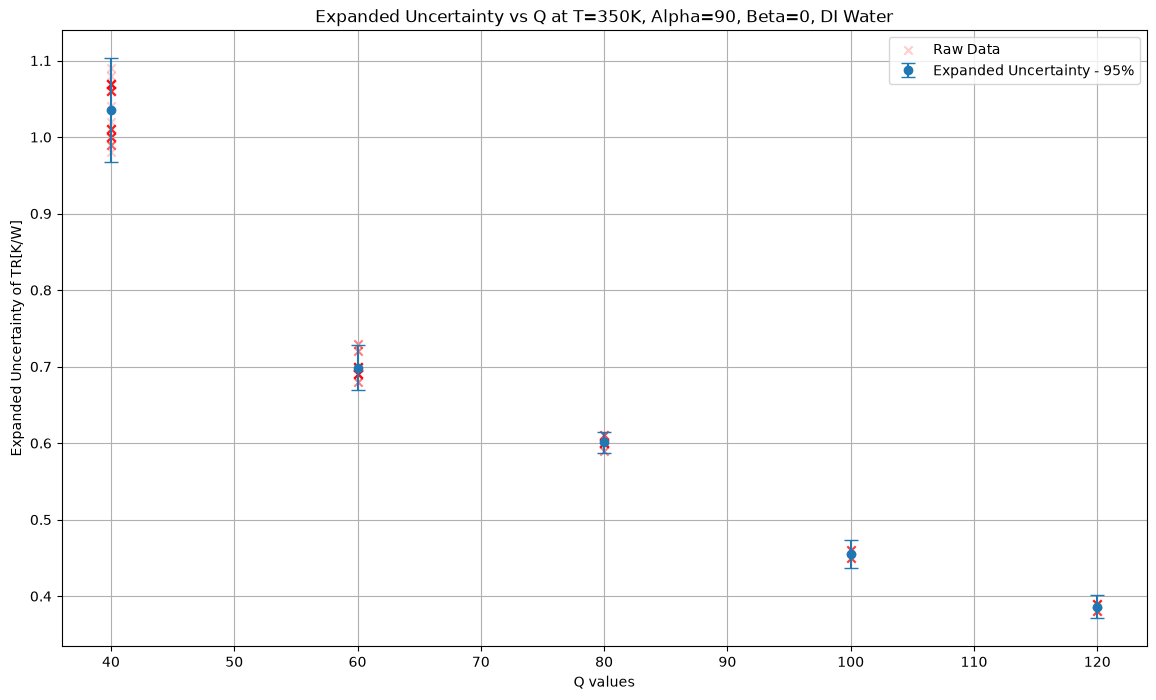

In [420]:
# plot expanded uncertainty for TR[K/W] at filtered temperature and Q
# X axis Q values and y axis expanded uncertainty of TR[K/W] errorbar

import matplotlib.pyplot as plt
Q_values = [40, 60, 80, 100, 120]

mean_Q40, expanded_Q40 = expanded_uncertainty(df_Q40_DIW_a90_b0_T_TR)
mean_Q60, expanded_Q60 = expanded_uncertainty(df_Q60_DIW_a90_b0_T_TR)
mean_Q80, expanded_Q80 = expanded_uncertainty(df_Q80_DIW_a90_b0_T_TR)
mean_Q100, expanded_Q100 = expanded_uncertainty(df_Q100_DIW_a90_b0_T_TR)
mean_Q120, expanded_Q120 = expanded_uncertainty(df_Q120_DIW_a90_b0_T_TR)

mean_values = [mean_Q40, mean_Q60, mean_Q80, mean_Q100, mean_Q120]
expanded_uncertainties = [expanded_Q40, expanded_Q60, expanded_Q80, expanded_Q100, expanded_Q120]

plt.figure(figsize=(14,8))
plt.errorbar(Q_values, mean_values, yerr=expanded_uncertainties, fmt='o', capsize=5, label='Expanded Uncertainty - 95%')
# plot raw data points for reference
plt.scatter([40]*len(df_Q40_DIW_a90_b0_T_TR), df_Q40_DIW_a90_b0_T_TR, color='red', alpha=0.2, label='Raw Data', marker='x')
plt.scatter([60]*len(df_Q60_DIW_a90_b0_T_TR), df_Q60_DIW_a90_b0_T_TR, color='red', alpha=0.5, marker='x')
plt.scatter([80]*len(df_Q80_DIW_a90_b0_T_TR), df_Q80_DIW_a90_b0_T_TR, color='red', alpha=0.5, marker='x')
plt.scatter([100]*len(df_Q100_DIW_a90_b0_T_TR), df_Q100_DIW_a90_b0_T_TR, color='red', alpha=0.5, marker='x')
plt.scatter([120]*len(df_Q120_DIW_a90_b0_T_TR), df_Q120_DIW_a90_b0_T_TR, color='red', alpha=0.5, marker='x')
plt.xlabel('Q values')
plt.ylabel('Expanded Uncertainty of TR[K/W]')
plt.title(f'Expanded Uncertainty vs Q at T={t}K, Alpha=90, Beta=0, DI Water')
plt.legend()
plt.grid()
plt.show()


# Machine Gnostic EU calculations

In [421]:
from machinegnostics.magcal import IntervalAnalysis

In [422]:
engine_q40 = IntervalAnalysis(n_points=30)

intv_q40 =engine_q40.fit(data=df_Q40_DIW_a90_b0_T_TR.to_numpy().reshape(-1))

# engine_q40.plot()



In [423]:
engine_q60 = IntervalAnalysis(n_points=30)
intv_q60 = engine_q60.fit(data=df_Q60_DIW_a90_b0_T_TR.to_numpy().reshape(-1))

In [424]:

engine_q80 = IntervalAnalysis(n_points=30)
intv_q80 = engine_q80.fit(data=df_Q80_DIW_a90_b0_T_TR.to_numpy().reshape(-1))

In [425]:
engine_q100 = IntervalAnalysis(n_points=30)
intv_q100 = engine_q100.fit(data=df_Q100_DIW_a90_b0_T_TR.to_numpy().reshape(-1))


In [426]:
engine_q120 = IntervalAnalysis(n_points=30)
intv_q120 = engine_q120.fit(data=df_Q120_DIW_a90_b0_T_TR.to_numpy().reshape(-1))

# engine_q120.plot()

In [427]:
intv_q120

array({'LB': 0.37497157341884696, 'LSB': 0.37974649988767417, 'DLB': 0.38, 'LCB': 0.38543, 'LSD': 0.388542580239009, 'ZL': 0.388163794608426, 'Z0L': 0.3897128532196395, 'Z0': 0.38996000000000003, 'Z0U': 0.390277204427729, 'ZU': 0.39167354666652865, 'USD': 0.391457419760991, 'UCB': 0.39, 'DUB': 0.39, 'USB': 0.39025350011232585, 'UB': 0.39501989145488486},
      dtype=object)

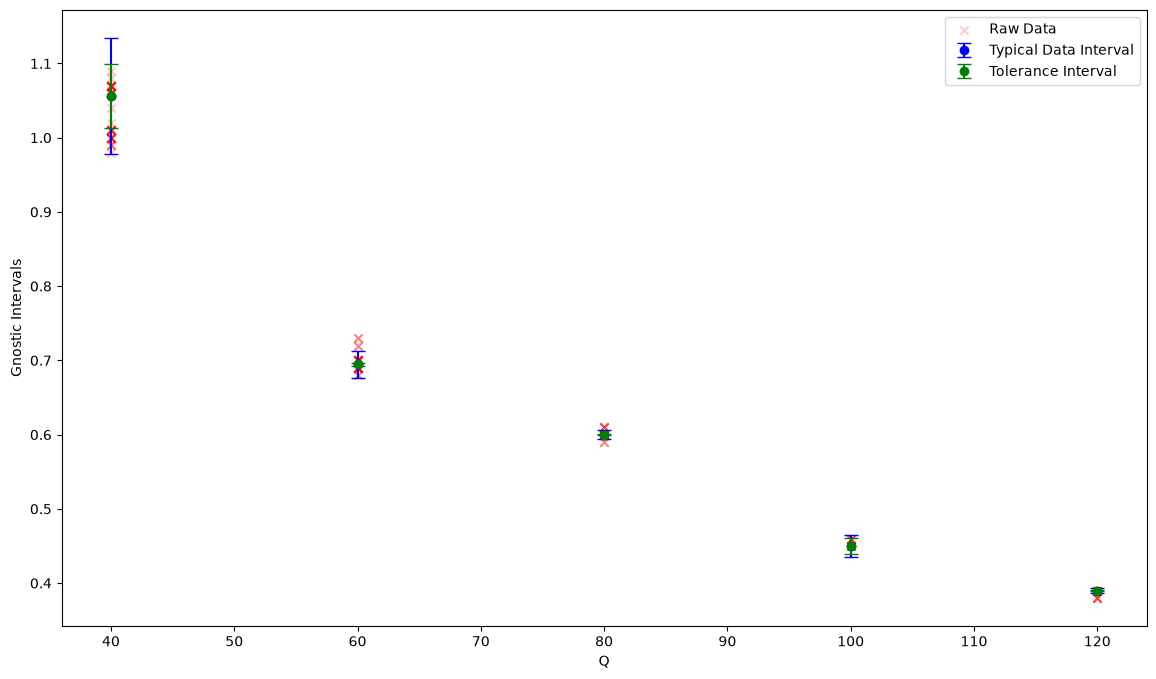

In [428]:
# plot intervals, x axis Q and y axis gnostic interval. mean, tolerance interval and typical data interval
import matplotlib.pyplot as plt

Q_values = [40, 60, 80, 100, 120]
intervals = [intv_q40, intv_q60, intv_q80, intv_q100, intv_q120]

plt.figure(figsize=(14, 8))
# plt.errorbar(Q_values, mean_values, yerr=expanded_uncertainties, fmt='o', capsize=5, label='Expanded Uncertainty - 95%')
# 40Q
plt.errorbar(40, intv_q40.item()['Z0'], 
             yerr=(intv_q40.item()['ZU'] - intv_q40.item()['ZL']),
             fmt='o', capsize=5, label='Typical Data Interval', color='blue')
plt.errorbar(40, intv_q40.item()['Z0'], 
             yerr=(intv_q40.item()['Z0U'] - intv_q40.item()['Z0L']),
             fmt='o', capsize=5, label='Tolerance Interval', color='green')

# 60Q
plt.errorbar(60, intv_q60.item()['Z0'], 
             yerr=(intv_q60.item()['ZU'] - intv_q60.item()['ZL']),
             fmt='o', capsize=5, color='blue')
plt.errorbar(60, intv_q60.item()['Z0'], 
             yerr=(intv_q60.item()['Z0U'] - intv_q60.item()['Z0L']),
             fmt='o', capsize=5, color='green')

# 80Q
plt.errorbar(80, intv_q80.item()['Z0'], 
             yerr=(intv_q80.item()['ZU'] - intv_q80.item()['ZL']),
             fmt='o', capsize=5, color='blue')
plt.errorbar(80, intv_q80.item()['Z0'], 
             yerr=(intv_q80.item()['Z0U'] - intv_q80.item()['Z0L']),
             fmt='o', capsize=5, color='green')

# 100Q
plt.errorbar(100, intv_q100.item()['Z0'], 
             yerr=(intv_q100.item()['ZU'] - intv_q100.item()['ZL']),
             fmt='o', capsize=5, color='blue')
plt.errorbar(100, intv_q100.item()['Z0'], 
             yerr=(intv_q100.item()['Z0U'] - intv_q100.item()['Z0L']),
             fmt='o', capsize=5, color='green')

# 120Q
plt.errorbar(120, intv_q120.item()['Z0'], 
             yerr=(intv_q120.item()['ZU'] - intv_q120.item()['ZL']),
             fmt='o', capsize=5, color='blue')
plt.errorbar(120, intv_q120.item()['Z0'], 
             yerr=(intv_q120.item()['Z0U'] - intv_q120.item()['Z0L']),
             fmt='o', capsize=5, color='green')

# raw data points for reference
plt.scatter([40]*len(df_Q40_DIW_a90_b0_T_TR), df_Q40_DIW_a90_b0_T_TR, color='red', alpha=0.2, label='Raw Data', marker='x')
plt.scatter([60]*len(df_Q60_DIW_a90_b0_T_TR), df_Q60_DIW_a90_b0_T_TR, color='red', alpha=0.5, marker='x')
plt.scatter([80]*len(df_Q80_DIW_a90_b0_T_TR), df_Q80_DIW_a90_b0_T_TR, color='red', alpha=0.5, marker='x')
plt.scatter([100]*len(df_Q100_DIW_a90_b0_T_TR), df_Q100_DIW_a90_b0_T_TR, color='red', alpha=0.5, marker='x')
plt.scatter([120]*len(df_Q120_DIW_a90_b0_T_TR), df_Q120_DIW_a90_b0_T_TR, color='red', alpha=0.5, marker='x')
plt.xlabel('Q')
plt.ylabel('Gnostic Intervals')
plt.legend()
plt.show()

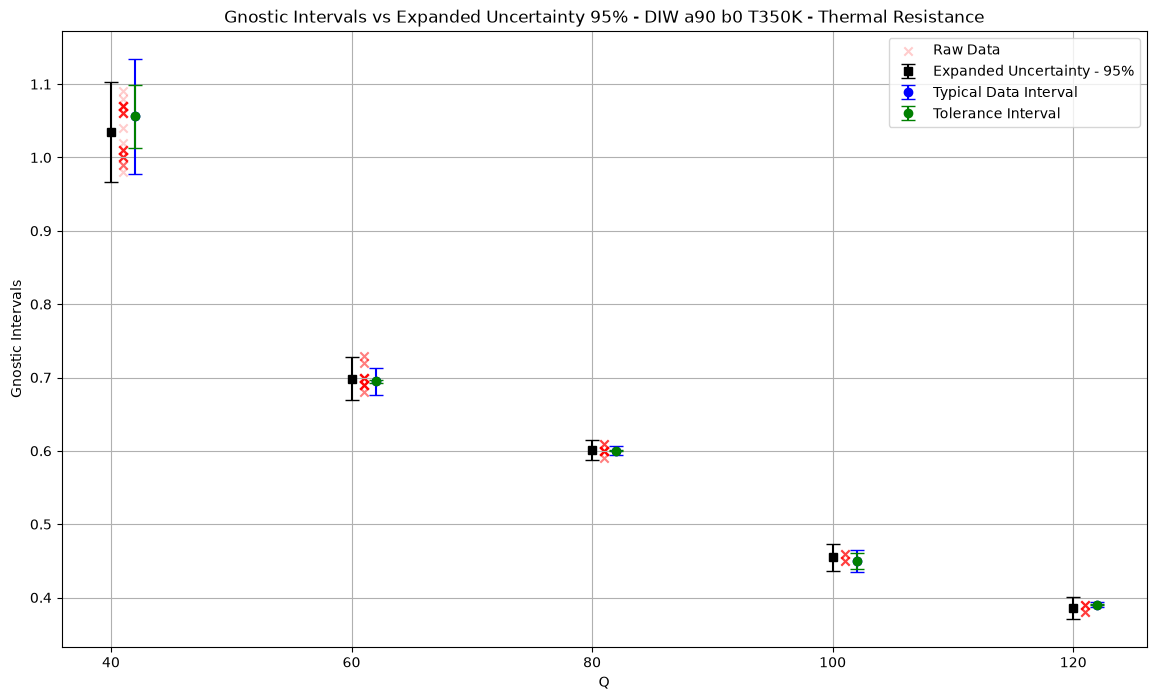

In [429]:
# plot intervals, x axis Q and y axis gnostic interval. mean, tolerance interval and typical data interval
import matplotlib.pyplot as plt

Q_values = [40, 60, 80, 100, 120]
intervals = [intv_q40, intv_q60, intv_q80, intv_q100, intv_q120]

plt.figure(figsize=(14, 8))
plt.errorbar(Q_values, mean_values, yerr=expanded_uncertainties, fmt='s', capsize=5, label='Expanded Uncertainty - 95%', color='black')
offset = 2
offset_raw = 1
# 40Q
plt.errorbar(40+offset, intv_q40.item()['Z0'], 
             yerr=(intv_q40.item()['ZU'] - intv_q40.item()['ZL']),
             fmt='o', capsize=5, label='Typical Data Interval', color='blue')
plt.errorbar(40+offset, intv_q40.item()['Z0'], 
             yerr=(intv_q40.item()['Z0U'] - intv_q40.item()['Z0L']),
             fmt='o', capsize=5, label='Tolerance Interval', color='green')

# 60Q
plt.errorbar(60+offset, intv_q60.item()['Z0'], 
             yerr=(intv_q60.item()['ZU'] - intv_q60.item()['ZL']),
             fmt='o', capsize=5, color='blue')
plt.errorbar(60+offset, intv_q60.item()['Z0'], 
             yerr=(intv_q60.item()['Z0U'] - intv_q60.item()['Z0L']),
             fmt='o', capsize=5, color='green')

# 80Q
plt.errorbar(80+offset, intv_q80.item()['Z0'], 
             yerr=(intv_q80.item()['ZU'] - intv_q80.item()['ZL']),
             fmt='o', capsize=5, color='blue')
plt.errorbar(80+offset, intv_q80.item()['Z0'], 
             yerr=(intv_q80.item()['Z0U'] - intv_q80.item()['Z0L']),
             fmt='o', capsize=5, color='green')

# 100Q
plt.errorbar(100+offset, intv_q100.item()['Z0'], 
             yerr=(intv_q100.item()['ZU'] - intv_q100.item()['ZL']),
             fmt='o', capsize=5, color='blue')
plt.errorbar(100+offset, intv_q100.item()['Z0'], 
             yerr=(intv_q100.item()['Z0U'] - intv_q100.item()['Z0L']),
             fmt='o', capsize=5, color='green')

# 120Q
plt.errorbar(120+offset, intv_q120.item()['Z0'], 
             yerr=(intv_q120.item()['ZU'] - intv_q120.item()['ZL']),
             fmt='o', capsize=5, color='blue')
plt.errorbar(120+offset, intv_q120.item()['Z0'], 
             yerr=(intv_q120.item()['Z0U'] - intv_q120.item()['Z0L']),
             fmt='o', capsize=5, color='green')

# raw data points for reference
plt.scatter([40+offset_raw]*len(df_Q40_DIW_a90_b0_T_TR), df_Q40_DIW_a90_b0_T_TR, color='red', alpha=0.2, label='Raw Data', marker='x')
plt.scatter([60+offset_raw]*len(df_Q60_DIW_a90_b0_T_TR), df_Q60_DIW_a90_b0_T_TR, color='red', alpha=0.5, marker='x')
plt.scatter([80+offset_raw]*len(df_Q80_DIW_a90_b0_T_TR), df_Q80_DIW_a90_b0_T_TR, color='red', alpha=0.5, marker='x')
plt.scatter([100+offset_raw]*len(df_Q100_DIW_a90_b0_T_TR), df_Q100_DIW_a90_b0_T_TR, color='red', alpha=0.5, marker='x')
plt.scatter([120+offset_raw]*len(df_Q120_DIW_a90_b0_T_TR), df_Q120_DIW_a90_b0_T_TR, color='red', alpha=0.5, marker='x')
plt.xlabel('Q')
plt.ylabel('Gnostic Intervals')
plt.legend()
plt.grid()
plt.title(f'Gnostic Intervals vs Expanded Uncertainty 95% - DIW a90 b0 T{t}K - Thermal Resistance')
plt.show()

# Intervals Summary Table

In [430]:
# table consisteing 95%EU with mean + gnostic mean (Z0) and tolerance intervals and typical data intervals

import pandas as pd
data = {
    'Q': [40, 60, 80, 100, 120],
    'mean stat': [mean_Q40, mean_Q60, mean_Q80, mean_Q100, mean_Q120],
    'EU 95': [expanded_Q40, expanded_Q60, expanded_Q80, expanded_Q100, expanded_Q120],
    'mean mg': [intv_q40.item()['Z0'], intv_q60.item()['Z0'], intv_q80.item()['Z0'], intv_q100.item()['Z0'], intv_q120.item()['Z0']],
    'Z0L': [intv_q40.item()['Z0L'], intv_q60.item()['Z0L'], intv_q80.item()['Z0L'], intv_q100.item()['Z0L'], intv_q120.item()['Z0L']],
    'Z0U': [intv_q40.item()['Z0U'], intv_q60.item()['Z0U'], intv_q80.item()['Z0U'], intv_q100.item()['Z0U'], intv_q120.item()['Z0U']],
    'ZL': [intv_q40.item()['ZL'], intv_q60.item()['ZL'], intv_q80.item()['ZL'], intv_q100.item()['ZL'], intv_q120.item()['ZL']],
    'ZU': [intv_q40.item()['ZU'], intv_q60.item()['ZU'], intv_q80.item()['ZU'], intv_q100.item()['ZU'], intv_q120.item()['ZU']]
}
df_intervals = pd.DataFrame(data)

In [431]:
df_intervals

,Q,mean stat,EU 95,mean mg,Z0L,Z0U,ZL,ZU
0,40,1.034898,0.067828,1.05623,1.017201,1.059864,0.982018,1.060148
1,60,0.698462,0.029294,0.69460,0.693432,0.695772,0.685908,0.704256
2,80,0.601111,0.013857,0.60006,0.599757,0.600344,0.596861,0.603258
3,100,0.455000,0.018374,0.45026,0.449571,0.460330,0.447772,0.462770
4,120,0.386000,0.015207,0.38996,0.389713,0.390277,0.388164,0.391674
